# Chapter 9 IDS phát hiện Botnet
Nguyễn Hoàng Gia Linh - CE181900

**Bản đã sửa cho Google Colab và Jupyter.** Chọn Restart session/kernel rồi Run all. Lần đầu có thể cần internet để cài scikit-learn 1.8.0.

Notebook chứa kết quả, biểu đồ và mô hình thật từ lần chạy trên Friday Morning; không cần upload ZIP để xem kết quả. `RUN_TRAINING=False` chỉ xem bản đã chạy. Muốn tính lại từ CSV, đổi thành True ở ô huấn luyện, rồi chọn CSV Friday Morning khi được yêu cầu. CSV gốc không được nhúng trong notebook.

Các output của bản sửa được kiểm tra bằng thực thi Python tại môi trường tạo file; chưa thực thi trực tiếp trong một phiên Google Colab.

In [1]:
# Chạy ô này trước. Kết quả và mô hình thật đã được đóng gói trong notebook.
from pathlib import Path
import base64, io, zipfile, sys, subprocess, importlib.metadata

# Cài thư viện còn thiếu trước khi import; mô hình được lưu với sklearn 1.8.0.
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "joblib": "joblib", "scikit-learn": "scikit-learn==1.8.0"}
to_install = []
for distribution, requirement in packages.items():
    try:
        version = importlib.metadata.version(distribution)
        if distribution == "scikit-learn" and version != "1.8.0":
            if "sklearn" in sys.modules:
                raise RuntimeError("Hãy Restart session/kernel rồi chạy lại từ ô đầu để dùng sklearn 1.8.0.")
            to_install.append(requirement)
    except importlib.metadata.PackageNotFoundError:
        to_install.append(requirement)
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *to_install])

# ROOT cố định trong phiên hiện tại; không phụ thuộc thư mục mở notebook.
ROOT = Path.cwd() / "CE181900_IDS_notebook_data"
ROOT.mkdir(parents=True, exist_ok=True)
PAYLOAD = "..."
# Chỉ giải nén bản kết quả gốc lần đầu, không ghi đè kết quả vừa huấn luyện lại.
if not (ROOT / ".original_artifacts_ready").exists():
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(PAYLOAD))) as archive:
        for info in archive.infolist():
            destination = (ROOT / info.filename).resolve()
            if not destination.is_relative_to(ROOT.resolve()):
                raise ValueError("Đường dẫn ZIP không hợp lệ")
        archive.extractall(ROOT)
    (ROOT / ".original_artifacts_ready").write_text("Original actual experiment artifacts", encoding="utf-8")
del PAYLOAD
RESULTS = ROOT / "results"
import json, pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
required = [RESULTS / "eda.json", ROOT / "model/ids_model.joblib", ROOT / "model/threshold.json"]
for path in required:
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu artifact: {path}. Xóa thư mục {ROOT} rồi chạy lại ô này để phục hồi bản gốc.")
print("Thư mục bài:", ROOT)
print("Đã có kết quả, biểu đồ và mô hình gốc; BENIGN=0, Bot=1.")


Thư mục bài: /workspace/scratch/04f52714855a/CE181900_IDS_notebook_data
Đã có kết quả, biểu đồ và mô hình gốc; BENIGN=0, Bot=1.


## 1 Toàn bộ logic huấn luyện
SMOTE, RFE, GridSearchCV và quy tắc lựa chọn threshold đều nằm trong ô dưới; cũng có trong source/ids_botnet_detection.py. Tách development/validation từ training70 giúp tránh chọn threshold trên test. Grid fit lại preprocessing và SMOTE trong từng fold.

In [2]:
"""CICIDS2017 Bot IDS. Run: python ids_botnet_detection.py --csv PATH --output DIR
SMOTE is implemented explicitly using sklearn nearest neighbours (no imblearn dependency).
Load the exported artifact with joblib.load; it contains only standard sklearn objects.
"""
import argparse, json, platform, time, warnings
from pathlib import Path
from typing import cast
from matplotlib.container import BarContainer
import numpy as np
import pandas as pd
import matplotlib
# Keep notebook plotting backend
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn import __version__ as sklearn_version
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

SEED=42
DROP=['Flow ID','Source IP','Destination IP','Source Port','Timestamp','Fwd Header Length.1']

def smote(X,y,random_state=42,k=5):
    """Binary SMOTE, minority to majority count; interpolate random k-nearest neighbours."""
    X=np.asarray(X,dtype=float); y=np.asarray(y,dtype=int)
    counts=np.bincount(y); minority=int(np.argmin(counts)); n=int(max(counts)-min(counts))
    if n==0: return X,y
    M=X[y==minority]; k=min(k,len(M)-1)
    if k<1: raise ValueError('SMOTE requires at least two minority observations')
    neighbors = NearestNeighbors(n_neighbors=k+1).fit(M)
    indices = np.asarray(neighbors.kneighbors(M, return_distance=False), dtype=np.intp)
    nn = indices[:, 1:]
    rng=np.random.default_rng(random_state); a=rng.integers(0,len(M),n)
    b=nn[a,rng.integers(0,k,n)]; u=rng.random((n,1))
    return np.vstack([X,M[a]+u*(M[b]-M[a])]),np.r_[y,np.full(n,minority)]

class SMOTEClassifier(ClassifierMixin,BaseEstimator):
    """Resamples only inside fit, including each GridSearchCV training fold."""
    def __init__(self,estimator: RandomForestClassifier | None=None,random_state=42):
        self.estimator=estimator; self.random_state=random_state
    def fit(self,X,y):
        Xr,yr=smote(X,y,self.random_state)
        if self.estimator is None:
            raise ValueError('SMOTEClassifier requires a RandomForestClassifier estimator')
        self.estimator_ = cast(RandomForestClassifier, clone(self.estimator))
        self.estimator_.fit(Xr, yr)
        self.classes_=self.estimator_.classes_; self.n_features_in_=X.shape[1]
        return self
    def predict(self,X): return self.estimator_.predict(X)
    def predict_proba(self,X): return self.estimator_.predict_proba(X)

def metrics(y,p,t=.5):
    pred=(np.asarray(p)>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(Accuracy=accuracy_score(y,pred),Precision=precision_score(y,pred,zero_division=0),
       Recall=recall_score(y,pred,zero_division=0),F1=f1_score(y,pred,zero_division=0),
       ROC_AUC=roc_auc_score(y,p),PR_AUC=average_precision_score(y,p),TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))

def main(csv,output):
    out=Path(output)
    for d in ['results','figures','model','source','notebook']: (out/d).mkdir(parents=True,exist_ok=True)
    res=out/'results'; fig=out/'figures'; start=time.time()
    def savefig(name): plt.tight_layout(); plt.savefig(fig/name,dpi=170,bbox_inches='tight'); plt.close()
    def log(x): print(x,flush=True)
    raw=pd.read_csv(csv,low_memory=False); raw.columns=raw.columns.str.strip(); raw.index.name='source_row_0based'
    labels=raw.Label.astype(str).str.strip()
    if not labels.isin(['BENIGN','Bot']).all(): raise ValueError('Unexpected labels')
    numeric=raw.drop(columns=['Label']).select_dtypes(include=np.number)
    schema=pd.DataFrame({'Feature':raw.columns,'dtype':raw.dtypes.astype(str).values,
      'missing':raw.isna().sum().values,'infinite':[int(np.isinf(raw[c]).sum()) if pd.api.types.is_numeric_dtype(raw[c]) else 0 for c in raw]})
    schema.to_csv(res/'data_schema.csv',index=False)
    eda={'raw_shape':list(raw.shape),'raw_class_counts':labels.value_counts().to_dict(),
      'raw_missing_cells':int(raw.isna().sum().sum()),'raw_infinite_cells':int(np.isinf(numeric).sum().sum()),
      'raw_exact_duplicates':int(raw.duplicated().sum()),'dropped_identifier_columns':DROP}
    raw.groupby(labels).size().rename('Count').to_csv(res/'class_counts.csv')
    plt.figure(figsize=(7, 4))
    ax = sns.countplot(x=labels, order=['BENIGN', 'Bot'])
    ax.set_ylim(0, float(labels.value_counts().max()) * 1.18)
    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(container, fmt='%.0f', padding=5)
    ax.set_title('Original class distribution', pad=15)
    ax.set_xlabel('Label')
    ax.set_ylabel('Number of flows')
    savefig('class_distribution.png')
    raw=raw.loc[~raw.duplicated()].copy()
    X=raw.drop(columns=['Label']+DROP,errors='ignore').apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
    y=raw.Label.str.strip().map({'BENIGN':0,'Bot':1}).astype(int)
    # Prevent identical predictor rows from appearing in different splits.
    # Contradictory predictor groups are excluded; consistent groups keep one record.
    hashes=pd.util.hash_pandas_object(X,index=False)
    group_labels=y.groupby(hashes).nunique(); conflicts=hashes.isin(group_labels[group_labels>1].index)
    eda['conflicting_predictor_rows_removed']=int(conflicts.sum())
    X=X.loc[~conflicts]; y=y.loc[X.index]
    dup=X.duplicated(); eda['additional_predictor_duplicates_removed']=int(dup.sum())
    X=X.loc[~dup]; y=y.loc[X.index]; raw=raw.loc[X.index]
    eda['clean_shape']=list(X.shape); eda['clean_class_counts']=y.value_counts().to_dict()
    Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=.30,stratify=y,random_state=SEED)
    Xdev,Xval,ydev,yval=train_test_split(Xtrain,ytrain,test_size=.20,stratify=ytrain,random_state=SEED)
    assert not set(Xdev.index)&set(Xtest.index) and not set(Xval.index)&set(Xtest.index)
    split=pd.DataFrame({'source_row_0based':X.index,'split':['development' if i in Xdev.index else 'validation' if i in Xval.index else 'test' for i in X.index],'y':y.values})
    split.to_csv(res/'split_manifest.csv',index=False)
    eda['splits']={n:{'rows':len(a),'benign':int((b==0).sum()),'bot':int((b==1).sum())} for n,a,b in [('train70',Xtrain,ytrain),('development56',Xdev,ydev),('validation14',Xval,yval),('test30',Xtest,ytest)]}
    (res/'eda.json').write_text(json.dumps(eda,indent=2),encoding='utf8'); log(eda)
    corr=Xdev.corr(); corr.to_csv(res/'correlation_matrix.csv')
    pairs=[(a,b,float(corr.loc[a,b])) for i,a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>.90]
    pd.DataFrame(pairs,columns=['Feature_1','Feature_2','Correlation']).to_csv(res/'high_correlation_pairs.csv',index=False)
    plt.figure(figsize=(13,11)); sns.heatmap(corr,cmap='coolwarm',vmin=-1,vmax=1,xticklabels=False,yticklabels=False); plt.title('Development data Pearson correlation (full labels in CSV)'); savefig('correlation_matrix.png')
    # Describe real outliers after train-only median imputation.
    imp=SimpleImputer(strategy='median',keep_empty_features=True).fit(Xdev)
    di=imp.transform(Xdev)
    scales=[]
    for name,scaler in [('StandardScaler',StandardScaler()),('RobustScaler',RobustScaler())]:
        z=scaler.fit_transform(di)
        for feature in ['Flow Bytes/s','Flow Packets/s','Flow Duration']:
            j=list(Xdev.columns).index(feature)
            scales.append({'Scaler':name,'Feature':feature,'Median':np.median(z[:,j]),'Q25':np.quantile(z[:,j],.25),'Q75':np.quantile(z[:,j],.75),'P99':np.quantile(z[:,j],.99),'Max':z[:,j].max()})
    pd.DataFrame(scales).to_csv(res/'scaling_comparison.csv',index=False)
    def pre(scaler='robust'):
        return Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),('variance',VarianceThreshold()),
          ('scale',RobustScaler() if scaler=='robust' else StandardScaler()),
          ('rfe',RFE(RandomForestClassifier(n_estimators=30,max_depth=12,class_weight='balanced',random_state=SEED,n_jobs=1),n_features_to_select=12,step=20))])
    prep=pre(); A=prep.fit_transform(Xdev,ydev); V=prep.transform(Xval); T=prep.transform(Xtest)
    valid=prep.named_steps['variance'].get_support(); names=X.columns[valid]; rfe=prep.named_steps['rfe']
    ranks=pd.DataFrame({'Feature':names,'Selected':rfe.support_,'Rank':rfe.ranking_})
    ranks=pd.concat([ranks,pd.DataFrame({'Feature':X.columns[~valid],'Selected':False,'Rank':np.nan})]); ranks.to_csv(res/'feature_selection.csv',index=False)
    selected=list(names[rfe.support_]); log('RFE selected: '+str(selected))
    models={'Decision Tree':DecisionTreeClassifier(max_depth=12,min_samples_leaf=2,random_state=SEED),
      'Random Forest':RandomForestClassifier(n_estimators=100,max_depth=None,n_jobs=1,random_state=SEED),
      'Gradient Boosting':GradientBoostingClassifier(n_estimators=100,max_depth=3,random_state=SEED)}
    Ar,yr=smote(A,ydev); eda['smote_counts']={str(k):int(v) for k,v in zip(*np.unique(yr,return_counts=True))}
    candidates={}; rows=[]; valrows=[]
    for experiment,xx,yy in [('A Original',A,ydev),('B SMOTE',Ar,yr)]:
        for name,model in models.items():
            key=name+' | '+experiment; log('Training '+key)
            m=clone(model).fit(xx,yy); candidates[key]=(prep,m)
            rows.append(dict(Model=name,Experiment=experiment,**metrics(ytest,m.predict_proba(T)[:,1])))
            valrows.append(dict(Candidate=key,**metrics(yval,m.predict_proba(V)[:,1])))
    # Explicit end-to-end CV: imputation/scaling/RFE/SMOTE fitted separately inside every fold.
    cache=out.parent/'.ids_cv_cache'
    gridpipe=Pipeline([('prep',pre()),('clf',SMOTEClassifier(RandomForestClassifier(random_state=SEED,n_jobs=1)))],memory=str(cache))
    grid={'clf__estimator__n_estimators':[40,80],'clf__estimator__max_depth':[10,None],'clf__estimator__min_samples_split':[2,10]}
    log('GridSearchCV: 8 configurations x 3 folds; preprocessing and SMOTE inside folds')
    search=GridSearchCV(gridpipe,grid,cv=StratifiedKFold(3,shuffle=True,random_state=SEED),scoring='f1',n_jobs=1,return_train_score=True,error_score='raise')
    search.fit(Xdev,ydev)
    pd.DataFrame(search.cv_results_).to_csv(res/'gridsearch_results.csv',index=False)
    best=search.best_estimator_; key='Random Forest Tuned | B SMOTE'; candidates[key]=(best.named_steps['prep'],best.named_steps['clf'].estimator_)
    rows.append(dict(Model='Random Forest Tuned',Experiment='B SMOTE',**metrics(ytest,best.predict_proba(Xtest)[:,1])))
    valrows.append(dict(Candidate=key,**metrics(yval,best.predict_proba(Xval)[:,1])))
    tuning={'best_params':search.best_params_,'best_cv_f1':float(search.best_score_),'folds':3,'scoring':'f1'}
    (res/'tuning.json').write_text(json.dumps(tuning,indent=2)); log(tuning)
    pd.DataFrame(rows).to_csv(res/'model_comparison.csv',index=False)
    pd.DataFrame(valrows).to_csv(res/'validation_model_comparison.csv',index=False)
    # Extra StandardScaler experiment using otherwise identical RFE and SMOTE RF.
    pstd=pre('standard'); ds=pstd.fit_transform(Xdev,ydev); xs,ys=smote(ds,ydev)
    ms=clone(models['Random Forest']).fit(xs,ys)
    stdrow=dict(Candidate='RF SMOTE StandardScaler',**metrics(yval,ms.predict_proba(pstd.transform(Xval))[:,1]))
    pd.DataFrame([stdrow,dict(Candidate='RF SMOTE RobustScaler',**metrics(yval,candidates['Random Forest | B SMOTE'][1].predict_proba(V)[:,1]))]).to_csv(res/'scaler_validation_metrics.csv',index=False)
    # Select model AND threshold using validation exclusively, never test outcomes.
    sweep=[]
    for name,(pp,mm) in candidates.items():
        pv=mm.predict_proba(pp.transform(Xval))[:,1]
        for t in np.round(np.arange(.1,1,.1),2): sweep.append(dict(Candidate=name,Threshold=t,**metrics(yval,pv,t)))
    sweep=pd.DataFrame(sweep); sweep.to_csv(res/'validation_thresholds_all_models.csv',index=False)
    feasible=sweep[sweep.Recall>=.95]
    if len(feasible): chosen=feasible.sort_values(['Precision','Recall','F1','Threshold'],ascending=[False,False,False,False]).iloc[0]; status='Validation recall target achieved'
    else: chosen=sweep.sort_values(['Recall','Precision','F1'],ascending=False).iloc[0]; status='No validation threshold on requested grid meets 95%; report limitation'
    name=chosen.Candidate; threshold=float(chosen.Threshold); pp,mm=candidates[name]
    finite = FunctionTransformer(np.nan_to_num, kw_args={'nan':np.nan,'posinf':np.nan,'neginf':np.nan}, feature_names_out='one-to-one')
    finite.set_output(transform='pandas')
    finite.fit(Xdev)
    final=Pipeline([('finite',finite)]+list(pp.steps)+[('classifier',mm)])
    pt=final.predict_proba(Xtest)[:,1]; finalmetrics=metrics(ytest,pt,threshold)
    config={'candidate':name,'threshold':threshold,'selection_dataset':'validation14','selection_rule':'Recall >= 0.95 then highest Precision; ties Recall/F1/threshold', 'selection_status':status,'validation_metrics':chosen.to_dict(),'test_metrics':finalmetrics,'feature_columns':list(X.columns),'selected_features':list(X.columns[pp.named_steps['variance'].get_support()][pp.named_steps['rfe'].support_]),'positive_label':'Bot','negative_label':'BENIGN','test_target_met':bool(finalmetrics['Recall']>=.95),'sklearn_version':sklearn_version}
    (out/'model'/'threshold.json').write_text(json.dumps(config,indent=2),encoding='utf8')
    joblib.dump(final,out/'model'/'ids_model.joblib',compress=3)
    restored=joblib.load(out/'model'/'ids_model.joblib'); assert np.allclose(pt[:20],restored.predict_proba(Xtest.iloc[:20])[:,1])
    th=sweep[sweep.Candidate==name].copy(); th.to_csv(res/'threshold_analysis.csv',index=False)
    pd.DataFrame([dict(Threshold=t,**metrics(ytest,pt,t)) for t in np.round(np.arange(.1,1,.1),2)]).to_csv(res/'test_threshold_analysis_descriptive.csv',index=False)
    plt.figure(figsize=(6,4))
    for metric in ['Precision','Recall','F1']: plt.plot(th.Threshold,th[metric],marker='o',label=metric)
    plt.axhline(.95,color='gray',ls='--',label='Recall target'); plt.axvline(threshold,color='black',ls=':'); plt.ylim(0,1.03); plt.xlabel('Threshold'); plt.title('Validation threshold selection'); plt.legend(); savefig('threshold_analysis.png')
    cm=confusion_matrix(ytest,pt>=threshold,labels=[0,1]); plt.figure(figsize=(5,4)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['NORMAL','BOT ALERT'],yticklabels=['BENIGN','Bot']); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Untouched test set at selected threshold'); savefig('confusion_matrix.png')
    fpr,tpr,_=roc_curve(ytest,pt); plt.figure(figsize=(5,4)); plt.plot(fpr,tpr,label=f"AUC = {finalmetrics['ROC_AUC']:.5f}"); plt.plot([0,1],[0,1],'--',color='gray'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); savefig('roc_curve.png')
    pr,re,_=precision_recall_curve(ytest,pt); plt.figure(figsize=(5,4)); plt.plot(re,pr,label=f"AP = {finalmetrics['PR_AUC']:.4f}"); plt.axhline(ytest.mean(),ls='--',color='gray',label='Bot prevalence'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); savefig('pr_curve.png')
    importance=pd.Series(mm.feature_importances_,index=config['selected_features']).sort_values(ascending=False)
    importance.rename_axis('Feature').rename('Importance').to_csv(res/'feature_importance.csv')
    plt.figure(figsize=(8,4)); importance.head(10).sort_values().plot.barh(); plt.xlabel('Impurity importance'); plt.title('Top 10 features of selected IDS'); savefig('feature_importance.png')
    error=raw.loc[Xtest.index].copy(); error['Actual']=ytest; error['Attack_probability']=pt; error['Predicted']=(pt>=threshold).astype(int)
    fp=error[(error.Actual==0)&(error.Predicted==1)]; fn=error[(error.Actual==1)&(error.Predicted==0)]
    fp.to_csv(res/'false_positive.csv'); fn.to_csv(res/'false_negative.csv')
    # Inspect every FN if fewer than ten exist. Add separately labelled validation FN
    # and correct near-threshold Bot examples to reach ten reviewed records, never fabricate FN.
    reviewed=fn.sort_values('Attack_probability').head(10).copy(); reviewed['Review_type']='Test False Negative'
    if len(reviewed)<10:
        extra=error[(error.Actual==1)&(error.Predicted==1)].sort_values('Attack_probability').head(10-len(reviewed)).copy(); extra['Review_type']='Test True Positive near threshold (NOT FN)'; reviewed=pd.concat([reviewed,extra])
    reviewed.to_csv(res/'error_review_10_samples.csv')
    bottrain=Xdev.loc[ydev==1,config['selected_features']].median(); normaltrain=Xdev.loc[ydev==0,config['selected_features']].median()
    pd.DataFrame({'BENIGN_train_median':normaltrain,'Bot_train_median':bottrain}).rename_axis('Feature').to_csv(res/'class_feature_medians.csv')
    # A replay of held-out recorded flows, not live capture or evidence of novel attack detection.
    ids=list(ytest[ytest==0].index[:5])+list(ytest[ytest==1].index[:5])
    stream=raw.loc[ids,['Source IP','Destination IP','Destination Port','Protocol']].copy(); stream['Actual']=ytest.loc[ids]
    p=restored.predict_proba(X.loc[ids])[:,1]; stream['Attack_probability']=p; stream['Threshold']=threshold; stream['Decision']=np.where(p>=threshold,'BOT ALERT','NORMAL'); stream.to_csv(res/'streaming_inference.csv')
    (res/'eda.json').write_text(json.dumps(eda,indent=2),encoding='utf8')
    (res/'runtime.json').write_text(json.dumps({'seconds':time.time()-start,'python':platform.python_version(),'sklearn':sklearn_version,'pandas':pd.__version__,'numpy':np.__version__},indent=2))
    log('FINAL '+json.dumps(config)); log('Saved model reload and probability equivalence passed')



In [ ]:
# False: xem kết quả có sẵn. True: huấn luyện lại, sẽ mất thời gian.
RUN_TRAINING = False
# Nếu chạy trên máy, có thể nhập đường dẫn CSV thực tế tại đây.
CSV_PATH = ""
if RUN_TRAINING:
    CSV = Path(CSV_PATH).expanduser() if CSV_PATH.strip() else ROOT / "data/Friday-WorkingHours-Morning.pcap_ISCX.csv"
    if not CSV.is_file():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("Hãy điền CSV_PATH bằng đường dẫn CSV Friday Morning trên máy rồi chạy lại ô này.")
        print("Chọn CSV Friday Morning có hai nhãn BENIGN và Bot.")
        uploaded = files.upload()
        choices = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
        if len(choices) != 1:
            raise ValueError("Mỗi lần chỉ chọn một CSV Friday Morning.")
        CSV = choices[0].resolve()
    main(str(CSV), str(ROOT))
    print("Đã tính lại kết quả từ CSV:", CSV)
else:
    print("Đang xem kết quả thực đã nhúng. Đổi RUN_TRAINING=True để huấn luyện lại.")

Đang xem kết quả thực đã nhúng. Đổi RUN_TRAINING=True để huấn luyện lại.


## 2 EDA và làm sạch
Bỏ định danh, cột lặp, duplicate và chuẩn hóa vô cực. Median, scaler, variance filter và RFE chỉ học từ dữ liệu train tương ứng. Bảng schema bên dưới có đầy đủ tên cột, dtype, missing và infinite.

In [4]:
eda=json.loads((RESULTS/'eda.json').read_text())
print(json.dumps(eda,indent=2,ensure_ascii=False))
print(pd.read_csv(RESULTS/'data_schema.csv').to_string(index=False))

{
  "raw_shape": [
    191033,
    85
  ],
  "raw_class_counts": {
    "BENIGN": 189067,
    "Bot": 1966
  },
  "raw_missing_cells": 28,
  "raw_infinite_cells": 216,
  "raw_exact_duplicates": 2,
  "dropped_identifier_columns": [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Source Port",
    "Timestamp",
    "Fwd Header Length.1"
  ],
  "conflicting_predictor_rows_removed": 0,
  "additional_predictor_duplicates_removed": 6886,
  "clean_shape": [
    184145,
    78
  ],
  "clean_class_counts": {
    "0": 182192,
    "1": 1953
  },
  "splits": {
    "train70": {
      "rows": 128901,
      "benign": 127534,
      "bot": 1367
    },
    "development56": {
      "rows": 103120,
      "benign": 102026,
      "bot": 1094
    },
    "validation14": {
      "rows": 25781,
      "benign": 25508,
      "bot": 273
    },
    "test30": {
      "rows": 55244,
      "benign": 54658,
      "bot": 586
    }
  },
  "smote_counts": {
    "0": 102026,
    "1": 102026
  }
}
                  

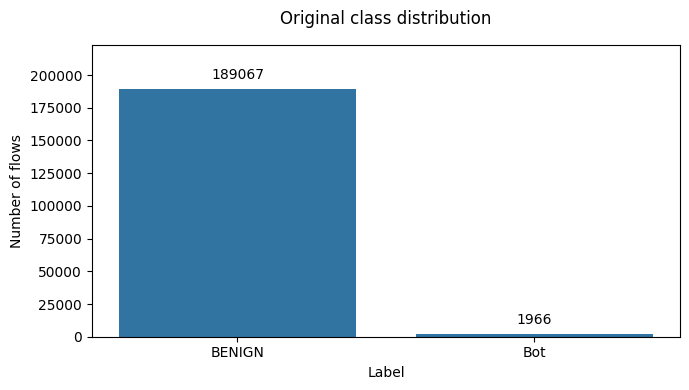

In [5]:
counts = json.loads((RESULTS / 'eda.json').read_text(encoding='utf-8'))['raw_class_counts']
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['BENIGN', 'Bot'], [counts['BENIGN'], counts['Bot']], color='#3274A1')
ax.set_ylim(0, max(counts.values()) * 1.18)
ax.bar_label(bars, fmt='%.0f', padding=5)
ax.set_title('Original class distribution', pad=15)
ax.set_xlabel('Label')
ax.set_ylabel('Number of flows')
fig.tight_layout()
fig.savefig(ROOT / 'figures/class_distribution.png', dpi=170, bbox_inches='tight')
plt.show()


## 3 Scaling và Feature Selection
RobustScaler dùng median/IQR để giảm ảnh hưởng traffic spike lên khoảng cách SMOTE. StandardScaler được so sánh bằng thí nghiệm RF SMOTE trên cùng validation. Feature hằng có Rank trống; Selected=True có Rank=1.

In [6]:
print(pd.read_csv(RESULTS/'scaling_comparison.csv').to_string(index=False))
print(pd.read_csv(RESULTS/'scaler_validation_metrics.csv').to_string(index=False))
print(pd.read_csv(RESULTS/'feature_selection.csv').to_string(index=False))
print(pd.read_csv(RESULTS/'high_correlation_pairs.csv').to_string(index=False))

        Scaler        Feature    Median       Q25       Q75        P99         Max
StandardScaler   Flow Bytes/s -0.069015 -0.069230 -0.058100   0.526991   88.087664
StandardScaler Flow Packets/s -0.230040 -0.230400 -0.141020   3.475778   14.594497
StandardScaler  Flow Duration -0.385989 -0.387021 -0.367779   3.404057    3.459928
  RobustScaler   Flow Bytes/s  0.000000 -0.019303  0.980697  53.552406 7921.069171
  RobustScaler Flow Packets/s  0.000000 -0.004035  0.995965  41.461225  165.859063
  RobustScaler  Flow Duration  0.000000 -0.053667  0.946333 196.959783  199.863261
              Candidate  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC    TN  FP  FN  TP
RF SMOTE StandardScaler  0.999767   0.981949 0.996337 0.989091 0.999998 0.999776 25503   5   1 272
  RF SMOTE RobustScaler  0.999573   0.971223 0.989011 0.980036 0.999978 0.998341 25500   8   3 270
                    Feature  Selected  Rank
           Destination Port      True   1.0
                   Protocol     Fa

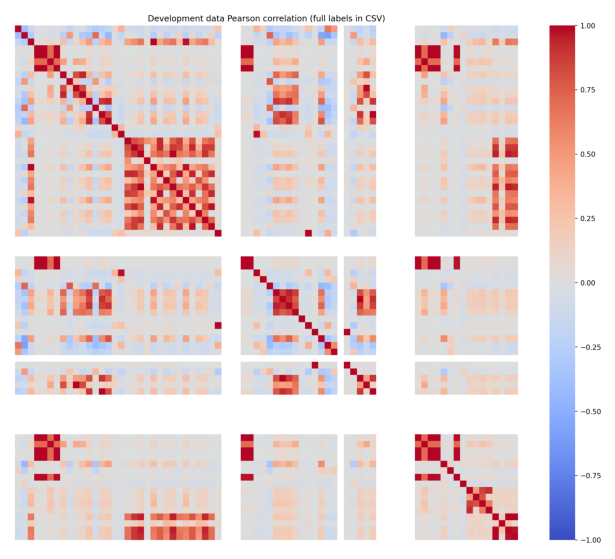

In [7]:
plt.figure(figsize=(9,7)); plt.imshow(plt.imread(ROOT/'figures'/'correlation_matrix.png')); plt.axis('off'); plt.show()

## 4 So sánh mô hình A và B
A dùng development gốc; B dùng SMOTE trên development. Test không resampling. Bảng comparison dùng threshold 0,50. PR_AUC = Average Precision (AP). Chọn candidate/threshold bằng validation, không bằng bảng test này.

In [8]:
print(pd.read_csv(RESULTS/'model_comparison.csv').to_string(index=False))
print('VALIDATION:')
print(pd.read_csv(RESULTS/'validation_model_comparison.csv').to_string(index=False))

              Model Experiment  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC    TN  FP  FN  TP
      Decision Tree A Original  0.999674   0.979730 0.989761 0.984720 0.995687 0.982992 54646  12   6 580
      Random Forest A Original  0.999710   0.993080 0.979522 0.986254 0.999127 0.997571 54654   4  12 574
  Gradient Boosting A Original  0.999566   0.989547 0.969283 0.979310 0.999972 0.997659 54652   6  18 568
      Decision Tree    B SMOTE  0.994370   0.655017 0.991468 0.788866 0.998960 0.979700 54352 306   5 581
      Random Forest    B SMOTE  0.999511   0.972927 0.981229 0.977060 0.999982 0.998429 54642  16  11 575
  Gradient Boosting    B SMOTE  0.997430   0.804945 1.000000 0.891933 0.999990 0.999092 54516 142   0 586
Random Forest Tuned    B SMOTE  0.999511   0.969748 0.984642 0.977138 0.999980 0.998171 54640  18   9 577
VALIDATION:
                     Candidate  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC    TN  FP  FN  TP
    Decision Tree | A Original  0.

## 5 GridSearchCV
8 cấu hình x 3 fold, scoring F1. RFE và SMOTE fit lại trong từng CV training fold. Tuning không bảo đảm thắng baseline trên test.

In [9]:
print((RESULTS/'tuning.json').read_text())
grid=pd.read_csv(RESULTS/'gridsearch_results.csv')
print(grid[['params','mean_test_score','std_test_score','rank_test_score']].to_string(index=False))

{
  "best_params": {
    "clf__estimator__max_depth": null,
    "clf__estimator__min_samples_split": 2,
    "clf__estimator__n_estimators": 40
  },
  "best_cv_f1": 0.9813174781700494,
  "folds": 3,
  "scoring": "f1"
}
                                                                                                          params  mean_test_score  std_test_score  rank_test_score
   {'clf__estimator__max_depth': 10, 'clf__estimator__min_samples_split': 2, 'clf__estimator__n_estimators': 40}         0.655304        0.005054                8
   {'clf__estimator__max_depth': 10, 'clf__estimator__min_samples_split': 2, 'clf__estimator__n_estimators': 80}         0.662861        0.013071                5
  {'clf__estimator__max_depth': 10, 'clf__estimator__min_samples_split': 10, 'clf__estimator__n_estimators': 40}         0.658096        0.007409                7
  {'clf__estimator__max_depth': 10, 'clf__estimator__min_samples_split': 10, 'clf__estimator__n_estimators': 80}         0.658376 

## 6 Threshold Analysis
Quét 0,10-0,90 trên validation; chọn Recall Bot ≥95% và Precision cao nhất. Giữ nguyên mô hình và threshold khi đánh giá test. Không refit sau lựa chọn.

In [10]:
config=json.loads((ROOT/'model'/'threshold.json').read_text())
print('Candidate:',config['candidate'])
print('Threshold:',config['threshold'])
print(pd.read_csv(RESULTS/'threshold_analysis.csv').to_string(index=False))
print('Untouched test metrics:',config['test_metrics'])

Candidate: Random Forest | B SMOTE
Threshold: 0.9
              Candidate  Threshold  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC    TN  FP  FN  TP
Random Forest | B SMOTE        0.1  0.996664   0.761905 0.996337 0.863492 0.999978 0.998341 25423  85   1 272
Random Forest | B SMOTE        0.2  0.998642   0.888889 0.996337 0.939551 0.999978 0.998341 25474  34   1 272
Random Forest | B SMOTE        0.3  0.999108   0.925170 0.996337 0.959436 0.999978 0.998341 25486  22   1 272
Random Forest | B SMOTE        0.4  0.999496   0.957746 0.996337 0.976661 0.999978 0.998341 25496  12   1 272
Random Forest | B SMOTE        0.5  0.999573   0.971223 0.989011 0.980036 0.999978 0.998341 25500   8   3 270
Random Forest | B SMOTE        0.6  0.999496   0.971014 0.981685 0.976321 0.999978 0.998341 25500   8   5 268
Random Forest | B SMOTE        0.7  0.999535   0.978022 0.978022 0.978022 0.999978 0.998341 25502   6   6 267
Random Forest | B SMOTE        0.8  0.999690   0.996255 0.974359 0.985

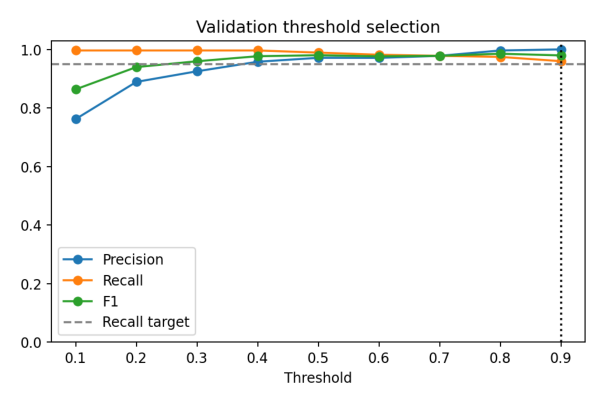

In [11]:
plt.figure(figsize=(9,5)); plt.imshow(plt.imread(ROOT/'figures'/'threshold_analysis.png')); plt.axis('off'); plt.show()

## 7 Confusion Matrix và Error Analysis
FP: BENIGN bị cảnh báo Bot, gây workload/alert fatigue. FN: Bot bị bỏ sót, tạo rủi ro an ninh. Kiểm tra report.pdf để xem diễn giải từng mẫu. Nếu FN ít hơn 10, không tạo thêm FN; mẫu bổ sung được ghi rõ là TP.

In [12]:
fp=pd.read_csv(RESULTS/'false_positive.csv');fn=pd.read_csv(RESULTS/'false_negative.csv')
print('FP:',len(fp),'FN:',len(fn))
review=pd.read_csv(RESULTS/'error_review_10_samples.csv')
print(review[['source_row_0based','Review_type','Attack_probability','Destination Port','Flow Duration','Bwd Packet Length Mean']].to_string(index=False))

FP: 1 FN: 27
 source_row_0based         Review_type  Attack_probability  Destination Port  Flow Duration  Bwd Packet Length Mean
             88941 Test False Negative            0.110000              2629             54                     6.0
            114001 Test False Negative            0.170000              4278             20                     6.0
             87243 Test False Negative            0.175714             52255              3                     6.0
            114113 Test False Negative            0.190000             52946              3                     6.0
            141987 Test False Negative            0.200000              8080          50856                     0.0
            111645 Test False Negative            0.220000             52872             54                     6.0
             88485 Test False Negative            0.379849             52262             45                     6.0
            105918 Test False Negative            0.469706 

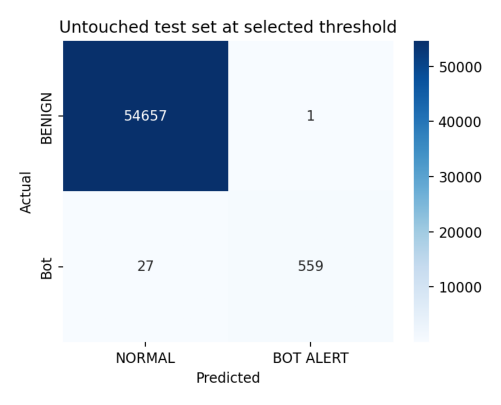

In [13]:
plt.figure(figsize=(9,5)); plt.imshow(plt.imread(ROOT/'figures'/'confusion_matrix.png')); plt.axis('off'); plt.show()

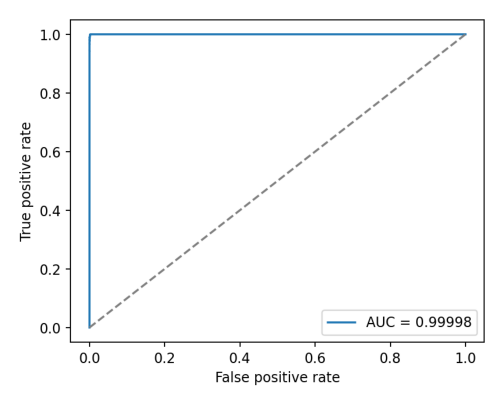

In [14]:
plt.figure(figsize=(9,5)); plt.imshow(plt.imread(ROOT/'figures'/'roc_curve.png')); plt.axis('off'); plt.show()

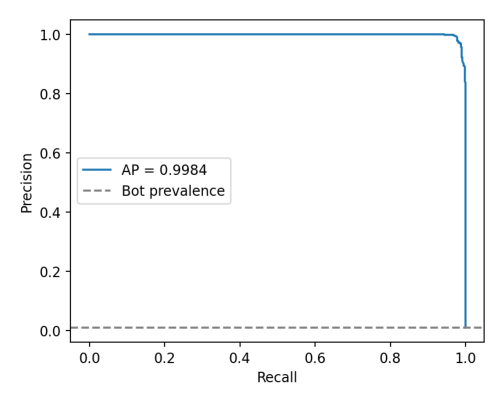

In [15]:
plt.figure(figsize=(9,5)); plt.imshow(plt.imread(ROOT/'figures'/'pr_curve.png')); plt.axis('off'); plt.show()

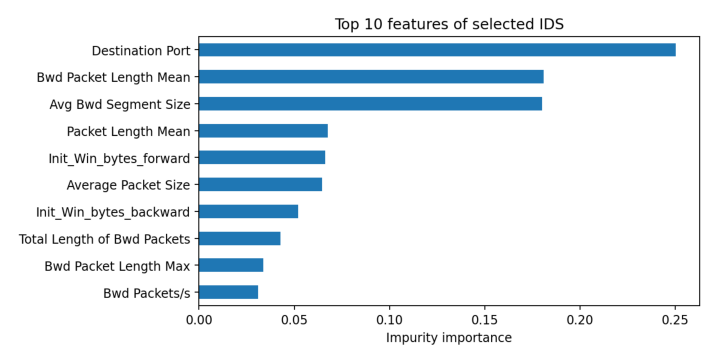

In [16]:
plt.figure(figsize=(9,5)); plt.imshow(plt.imread(ROOT/'figures'/'feature_importance.png')); plt.axis('off'); plt.show()

## 8 Streaming inference từ mô hình đã lưu
Replay 10 flow test thật. Dùng đúng threshold JSON, không mặc định 0,50. Đây là replay, không phải bắt gói tin trực tiếp. Với CSV flow khác, chạy source/stream_inference.py.

In [17]:
config = json.loads((ROOT / "model/threshold.json").read_text(encoding="utf-8"))
print(pd.read_csv(RESULTS / "streaming_inference.csv").to_string(index=False))
model = joblib.load(ROOT / "model/ids_model.joblib")
print("Saved pipeline steps:", list(model.named_steps))
print("Selected threshold:", config["threshold"])
# Tính lại dự đoán trên các FN đã xuất để kiểm tra mô hình thật hoạt động.
fn_flows = pd.read_csv(RESULTS / "false_negative.csv")
if not fn_flows.empty:
    inputs = fn_flows[config["feature_columns"]].apply(pd.to_numeric, errors="coerce")
    probability = model.predict_proba(inputs)[:, 1]
    assert np.allclose(probability, fn_flows["Attack_probability"].to_numpy())
    print("Đã kiểm tra score của", len(fn_flows), "flow FN bằng mô hình tải lại: khớp.")


 source_row_0based      Source IP Destination IP  Destination Port  Protocol  Actual  Attack_probability  Threshold  Decision
             57312   192.168.10.3   192.168.10.1                53        17       0                0.00        0.9    NORMAL
             49437   192.168.10.5  50.63.243.230                80         6       0                0.00        0.9    NORMAL
            148687 104.97.117.153   192.168.10.8              4255         6       0                0.00        0.9    NORMAL
             91590 162.208.20.178   192.168.10.5             53210         6       0                0.00        0.9    NORMAL
             82615  192.168.10.14   192.168.10.3                53        17       0                0.00        0.9    NORMAL
            104183 205.174.165.73  192.168.10.15             52712         6       1                0.98        0.9 BOT ALERT
            170038  192.168.10.14 205.174.165.73              8080         6       1                1.00        0.9 BO

## 9 Kết luận và hạn chế
Đọc Recall/Precision test trong ô trên để kiểm tra mục tiêu. Kết quả trên một file, chia ngẫu nhiên theo flow; chưa chứng minh khái quát theo host/time hoặc Botnet mới. SMOTE có thể nội suy feature rời rạc thành số phân số; score chưa calibration. Không được tự đổi threshold dựa trên test để tuyên bố đạt yêu cầu.

Tài liệu nguồn: Chapter9_IDS_Botnet_Lab_Assignment.docx và CSV gốc do người dùng cung cấp. Các giá trị thực đo có trong results; phân tích đầy đủ và từng dòng FN trong report.pdf.